# Лабораторная работа 2

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import shutil
import subprocess
import tarfile
from pathlib import Path

if not Path('repo').exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/JustHawker/AIT_Course_SamU_2026.git', 'repo'], check=True)
if not Path('scripts').exists():
    shutil.copytree(Path('repo', 'lab_1-2', 'scripts'), 'scripts')

cifar_dir = Path('scripts', 'datasets', 'cifar-10-batches-py')
if not cifar_dir.exists():
    with tarfile.open(Path('..', 'cifar-10-python.tar.gz')) as archive:
        if hasattr(tarfile, 'data_filter'):
            archive.extractall(Path('scripts', 'datasets'), filter='data')
        else:
            archive.extractall(Path('scripts', 'datasets'))

In [2]:
%%writefile scripts/classifiers/neural_net.py
import numpy as np

class TwoLayerNet(object):
    # Двухслойная сеть: вход -> полносвязный слой -> ReLU -> полносвязный слой -> softmax

    def __init__(self, input_size, hidden_size, output_size, std=1e-4):
        # Веса заполняются маленькими случайными числами, смещения нулями
        self.params = {}
        self.params['W1'] = std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

    def loss(self, X, y=None, reg=0.0):
        # Без y возвращает очки классов; с y возвращает потерю и градиенты по всем весам
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        N = X.shape[0]

        # Прямой проход
        z1 = X.dot(W1) + b1
        h = np.maximum(0, z1)
        scores = h.dot(W2) + b2

        if y is None:
            return scores

        # Вероятности классов через softmax (из оценок вычитается максимум строки)
        shifted = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)
        loss = -np.mean(np.log(probs[np.arange(N), y]))
        loss += reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        # Обратный проход: от выхода к входу
        grads = {}
        dscores = probs.copy()
        dscores[np.arange(N), y] -= 1
        dscores /= N

        grads['W2'] = h.T.dot(dscores) + 2 * reg * W2
        grads['b2'] = dscores.sum(axis=0)

        dh = dscores.dot(W2.T)
        dh[z1 <= 0] = 0  # ReLU пропускает градиент только там, где нейрон был активен
        grads['W1'] = X.T.dot(dh) + 2 * reg * W1
        grads['b1'] = dh.sum(axis=0)

        return loss, grads

    def train(self, X, y, X_val, y_val,
              learning_rate=1e-3, learning_rate_decay=0.95,
              reg=5e-6, num_iters=100,
              batch_size=200, verbose=False):
        # Обучение стохастическим градиентным спуском; возвращает историю потерь и точности
        num_train = X.shape[0]
        iterations_per_epoch = max(num_train // batch_size, 1)

        loss_history = []
        train_acc_history = []
        val_acc_history = []

        for it in range(num_iters):
            idx = np.random.choice(num_train, batch_size, replace=True)
            X_batch = X[idx]
            y_batch = y[idx]

            loss, grads = self.loss(X_batch, y=y_batch, reg=reg)
            loss_history.append(loss)

            for name in self.params:
                self.params[name] -= learning_rate * grads[name]

            if verbose and it % 100 == 0:
                print('iteration %d / %d: loss %f' % (it, num_iters, loss))

            # Раз в эпоху: запомнить точность и уменьшить скорость обучения
            if it % iterations_per_epoch == 0:
                train_acc = (self.predict(X_batch) == y_batch).mean()
                val_acc = (self.predict(X_val) == y_val).mean()
                train_acc_history.append(train_acc)
                val_acc_history.append(val_acc)
                learning_rate *= learning_rate_decay

        return {
            'loss_history': loss_history,
            'train_acc_history': train_acc_history,
            'val_acc_history': val_acc_history,
        }

    def predict(self, X):
        # Класс с наибольшим количеством очков
        return np.argmax(self.loss(X), axis=1)

Overwriting scripts/classifiers/neural_net.py


In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.classifiers.neural_net import TwoLayerNet

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

def rel_error(x, y):
    # Относительная ошибка между двумя массивами
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [4]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных.

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [5]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [6]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.7985612998927536e-13


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2.


In [7]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447625e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738421e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


Final training loss:  0.017149607938732093


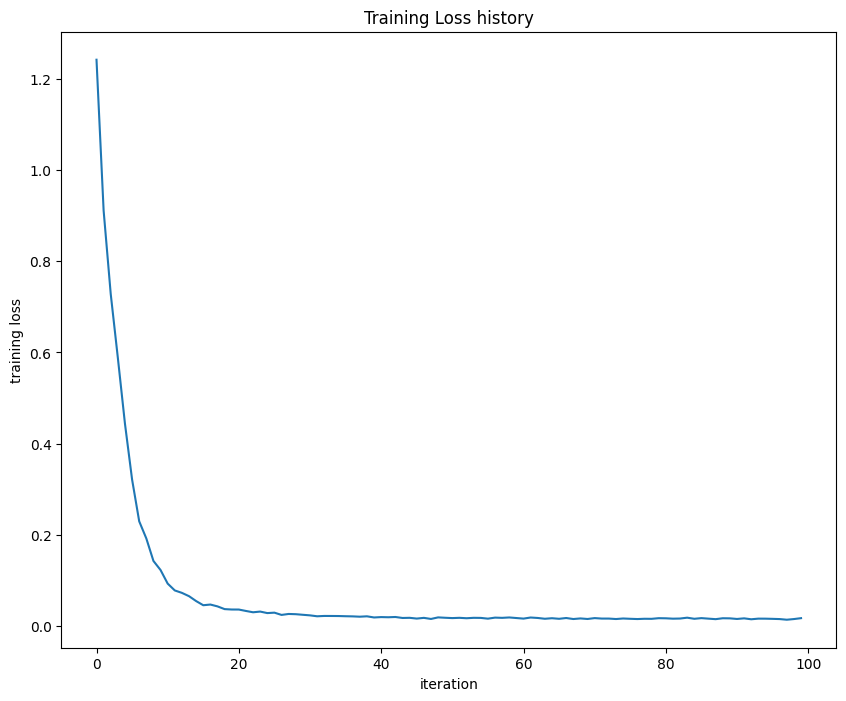

In [8]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])

plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту.

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1.

Обучите нейронную сеть на ваших данных.

При сдаче лабораторной работы объясните значения всех параметров метода train.

In [9]:
# Загрузка CIFAR-10 и разбиение на обучающую, валидационную и тестовую выборки
from scripts.data_utils import load_CIFAR10

X_train, y_train, X_test, y_test = load_CIFAR10('scripts/datasets/cifar-10-batches-py')

num_training, num_validation, num_test = 49000, 1000, 1000
X_val = X_train[num_training:num_training + num_validation]
y_val = y_train[num_training:num_training + num_validation]
X_train = X_train[:num_training]
y_train = y_train[:num_training]
X_test = X_test[:num_test]
y_test = y_test[:num_test]

# Предобработка: каждая картинка — строка из 3072 чисел, из всех вычитается среднее изображение
X_train = X_train.reshape(num_training, -1)
X_val = X_val.reshape(num_validation, -1)
X_test = X_test.reshape(num_test, -1)

mean_image = np.mean(X_train, axis=0)
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image

print('Обучающая:     ', X_train.shape, y_train.shape)
print('Валидационная: ', X_val.shape, y_val.shape)
print('Тестовая:      ', X_test.shape, y_test.shape)

Обучающая:      (49000, 3072) (49000,)
Валидационная:  (1000, 3072) (1000,)
Тестовая:       (1000, 3072) (1000,)


In [10]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-4, learning_rate_decay=0.95,
            reg=0.25, verbose=True)

val_acc = (net.predict(X_val) == y_val).mean()
print('Validation accuracy: ', val_acc)

iteration 0 / 1000: loss 2.302954
iteration 100 / 1000: loss 2.302550
iteration 200 / 1000: loss 2.297648
iteration 300 / 1000: loss 2.259602
iteration 400 / 1000: loss 2.204170
iteration 500 / 1000: loss 2.118565
iteration 600 / 1000: loss 2.051535
iteration 700 / 1000: loss 1.988466
iteration 800 / 1000: loss 2.006591
iteration 900 / 1000: loss 1.951473
Validation accuracy:  0.287


Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29.

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др.

Для лучшей модели вычислите acсuracy на тестовом наборе.

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков.

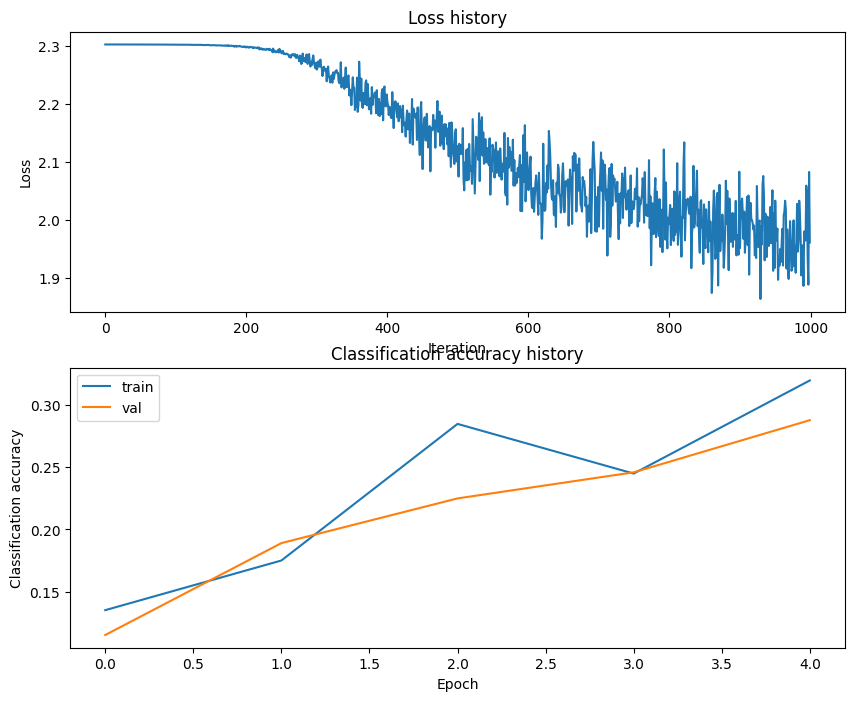

In [11]:
plt.subplot(2, 1, 1)
plt.plot(stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(stats['train_acc_history'], label='train')
plt.plot(stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.show()

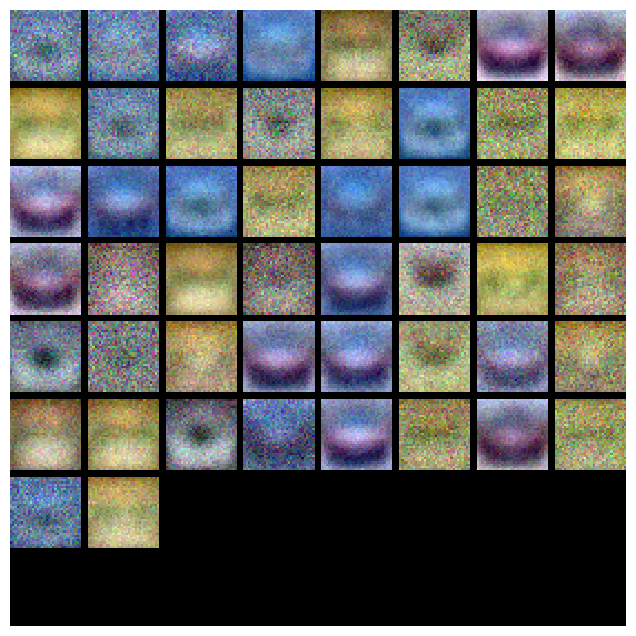

In [12]:
from scripts.vis_utils import visualize_grid

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

show_net_weights(net)

In [13]:
# Перебор параметров: размер скрытого слоя, скорость обучения, регуляризация; оценка по валидационной выборке
hidden_sizes = [100, 200]
learning_rates = [5e-4, 1e-3, 2e-3]
regs = [0.05, 0.25]

results = {}
best_val = -1
best_net = None

for hs in hidden_sizes:
    for lr in learning_rates:
        for reg in regs:
            candidate = TwoLayerNet(input_size, hs, num_classes)
            with np.errstate(over='ignore', invalid='ignore'):
                st = candidate.train(X_train, y_train, X_val, y_val,
                                     num_iters=2000, batch_size=200,
                                     learning_rate=lr, learning_rate_decay=0.95,
                                     reg=reg, verbose=False)
                acc = (candidate.predict(X_val) == y_val).mean()
            results[(hs, lr, reg)] = acc
            print('hidden = %3d, lr = %.0e, reg = %.2f: val accuracy = %.3f' % (hs, lr, reg, acc))
            if acc > best_val:
                best_val, best_net, best_stats, best_params = acc, candidate, st, (hs, lr, reg)

print('\nЛучшие параметры: hidden = %d, lr = %.0e, reg = %.2f, val accuracy = %.3f' % (*best_params, best_val))

hidden = 100, lr = 5e-04, reg = 0.05: val accuracy = 0.503
hidden = 100, lr = 5e-04, reg = 0.25: val accuracy = 0.488
hidden = 100, lr = 1e-03, reg = 0.05: val accuracy = 0.503
hidden = 100, lr = 1e-03, reg = 0.25: val accuracy = 0.486
hidden = 100, lr = 2e-03, reg = 0.05: val accuracy = 0.480
hidden = 100, lr = 2e-03, reg = 0.25: val accuracy = 0.485
hidden = 200, lr = 5e-04, reg = 0.05: val accuracy = 0.507
hidden = 200, lr = 5e-04, reg = 0.25: val accuracy = 0.482
hidden = 200, lr = 1e-03, reg = 0.05: val accuracy = 0.503
hidden = 200, lr = 1e-03, reg = 0.25: val accuracy = 0.513
hidden = 200, lr = 2e-03, reg = 0.05: val accuracy = 0.503
hidden = 200, lr = 2e-03, reg = 0.25: val accuracy = 0.498

Лучшие параметры: hidden = 200, lr = 1e-03, reg = 0.25, val accuracy = 0.513


iteration 0 / 5000: loss 2.304148
iteration 100 / 5000: loss 1.935689
iteration 200 / 5000: loss 1.789863
iteration 300 / 5000: loss 1.592127
iteration 400 / 5000: loss 1.538163
iteration 500 / 5000: loss 1.551703
iteration 600 / 5000: loss 1.520517
iteration 700 / 5000: loss 1.655995
iteration 800 / 5000: loss 1.584251
iteration 900 / 5000: loss 1.518270
iteration 1000 / 5000: loss 1.490879
iteration 1100 / 5000: loss 1.514201
iteration 1200 / 5000: loss 1.579792
iteration 1300 / 5000: loss 1.486993
iteration 1400 / 5000: loss 1.480078
iteration 1500 / 5000: loss 1.367498
iteration 1600 / 5000: loss 1.370607
iteration 1700 / 5000: loss 1.375675
iteration 1800 / 5000: loss 1.469979
iteration 1900 / 5000: loss 1.487985
iteration 2000 / 5000: loss 1.362479
iteration 2100 / 5000: loss 1.337658
iteration 2200 / 5000: loss 1.457178
iteration 2300 / 5000: loss 1.410469
iteration 2400 / 5000: loss 1.367030
iteration 2500 / 5000: loss 1.306651
iteration 2600 / 5000: loss 1.386144
iteration 270

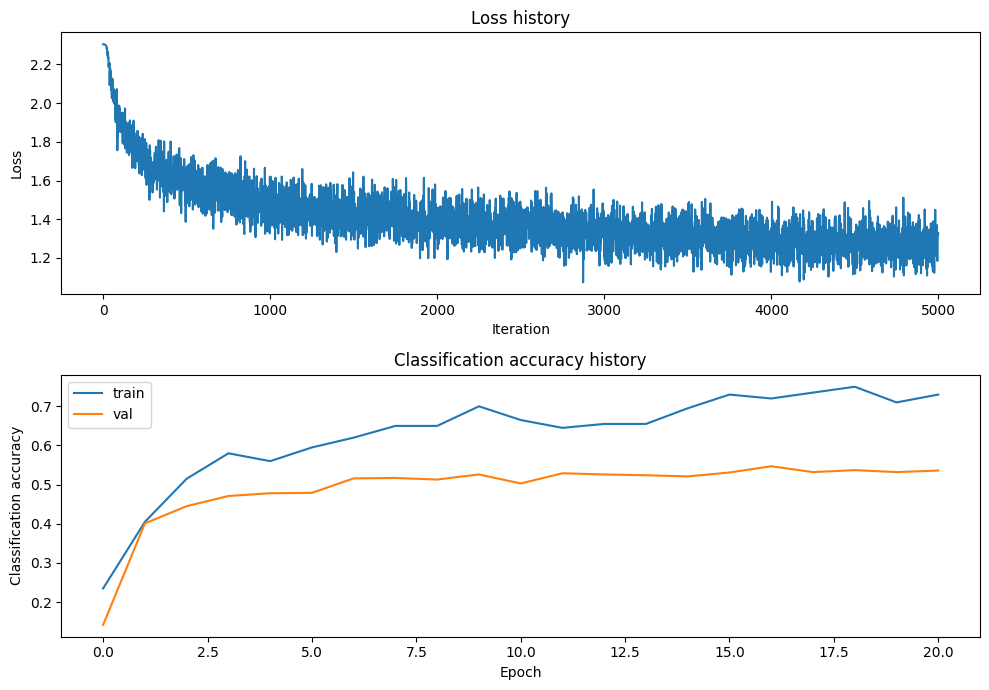

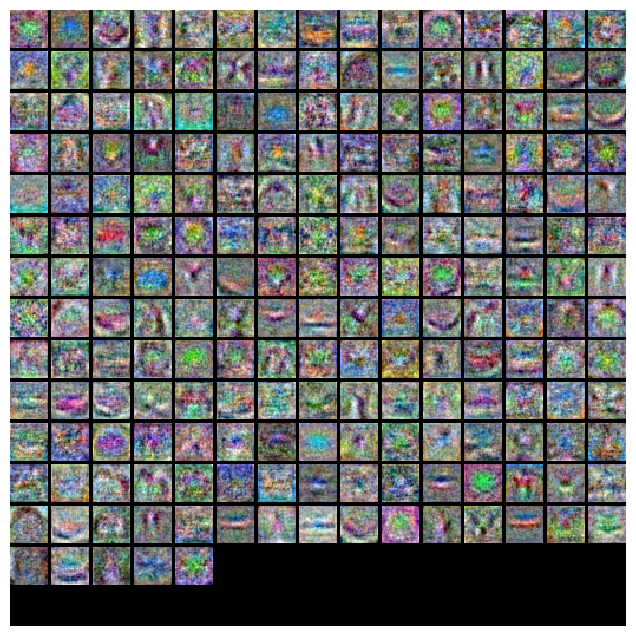

In [14]:
# Обучение сети с лучшими параметрами (5000 шагов) и проверка на тестовой выборке
hs, lr, reg = best_params
final_net = TwoLayerNet(input_size, hs, num_classes)
final_stats = final_net.train(X_train, y_train, X_val, y_val,
                              num_iters=5000, batch_size=200,
                              learning_rate=lr, learning_rate_decay=0.95,
                              reg=reg, verbose=True)

val_acc = (final_net.predict(X_val) == y_val).mean()
test_acc = (final_net.predict(X_test) == y_test).mean()
print('Validation accuracy: %.3f' % val_acc)
print('Test accuracy:       %.3f' % test_acc)

plt.figure(figsize=(10, 7))
plt.subplot(2, 1, 1)
plt.plot(final_stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(final_stats['train_acc_history'], label='train')
plt.plot(final_stats['val_acc_history'], label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()
plt.tight_layout()
plt.show()

show_net_weights(final_net)

Сделайте выводы по результатам работы.

**Выводы**

1. Реализована двухслойная полносвязная нейронная сеть: вход → полносвязный слой → ReLU → полносвязный слой → softmax, с L2-регуляризацией весов. Реализованы прямой проход, функция потерь, обратный проход (градиенты), обучение стохастическим градиентным спуском и предсказание.

2. Реализация проверена на модельных данных: выход сети совпал с эталоном (разница 3.7e-8), функция потерь тоже (разница 1.8e-13), а градиенты совпали с численными (относительная ошибка не больше 3.6e-9 для W1, b1, W2, b2). На модельных данных потеря снизилась до 0.017.

3. На CIFAR-10 с параметрами по умолчанию точность на валидации составила 0.287. По графикам видно, что сеть недообучена: первые 200 шагов потеря почти не меняется, а к концу обучения ещё продолжает падать. Причина — слишком маленькая скорость обучения (1e-4) и малое число шагов.

4. Перебор параметров (размер скрытого слоя 100 и 200, скорость обучения 5e-4, 1e-3, 2e-3, регуляризация 0.05 и 0.25) показал, что почти все комбинации дают точность 0.48–0.51. Лучшая комбинация: 200 нейронов, скорость обучения 1e-3, регуляризация 0.25 (0.513).

5. После обучения лучшей модели в течение 5000 шагов (около 20 эпох) точность на валидации составила 0.536, на тестовой выборке 0.524.

6. На графиках видно, что точность на обучающих данных (около 0.73) заметно выше, чем на валидационных (около 0.53): модель начинает переобучаться, а точность на валидации после 6-й эпохи растёт очень медленно (от 0.52 до 0.55). Уменьшить переобучение можно более сильной регуляризацией, dropout или увеличением данных.

7. Веса первого слоя у обученной сети похожи на шаблоны с краями, полосами и цветовыми переходами, а у недообученной сети это были размытые цветные пятна.

8. Сравнение методов на CIFAR-10: kNN — 0.282, линейный SVM — 0.363, двухслойная сеть — 0.524. Скрытый слой с нелинейностью ReLU позволяет сети строить более сложные признаки, чем один линейный шаблон на класс.

**Параметры метода train**

- X, y — обучающие данные и их метки классов.
- X_val, y_val — валидационные данные; используются только для контроля точности после каждой эпохи, на них сеть не учится.
- learning_rate — скорость обучения: размер шага, на который меняются веса против градиента. Слишком маленькая — обучение идёт очень медленно, слишком большая — обучение расходится.
- learning_rate_decay — множитель, на который уменьшается скорость обучения после каждой эпохи (0.95 — на 5 %). Позволяет в начале делать крупные шаги, а в конце точнее подстраивать веса.
- reg — сила L2-регуляризации: штраф за большие веса, который снижает переобучение.
- num_iters — общее число шагов обучения.
- batch_size — сколько случайных изображений используется на одном шаге для оценки градиента. Эпоха — это число шагов, за которые сеть в среднем увидит все обучающие данные (49000 / 200 = 245 шагов).
- verbose — выводить ли значение функции потерь каждые 100 шагов.